# ResNet50 Transfer Learning for Urban Street Classification

**Lien Pham individual notebook**

This notebook evaluates an ImageNet-pretrained **ResNet50** on the Kaggle *Tree Dataset of Urban Street Classification*.

The experiment has three purposes:
1. Inspect the dataset and justify the preprocessing strategy;
2. Establish a baseline ResNet50 transfer-learning result;
3. Investigate exact train/validation duplicates and perform a controlled second run after removing the duplicate training copies.

The original and cleaned experiments use the **same model architecture, pretrained weights, preprocessing, augmentation, optimizer, learning rate, batch size, number of epochs, validation set, and test set**. The only intended change is duplicate removal from the training set.

## 1. Dataset inspection

The dataset contains 4,804 JPEG images in three predefined splits: 3,850 training, 482 validation, and 472 test images. The test set is kept untouched throughout the experiments.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import copy
import hashlib
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

In [2]:
dataset_path = Path(r"D:\NEUTRAL_TOMMI\GROUPPROJECT\tree")
cleaned_dataset_path = dataset_path.parent / "cleaned_dataset"

assert dataset_path.exists(), f"Dataset not found: {dataset_path}"
assert cleaned_dataset_path != dataset_path

print("Dataset:", dataset_path)
for split in ["train", "val", "test"]:
    print(f"{split}: {(dataset_path / split).exists()}")

Dataset: D:\NEUTRAL_TOMMI\GROUPPROJECT\tree
train: True
val: True
test: True


In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".tif", ".gif", ".webp"}

def count_images(folder):
    return sum(
        1 for file in Path(folder).rglob("*")
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )

counts = {split: count_images(dataset_path / split) for split in ["train", "val", "test"]}
print(counts)
print("Total:", sum(counts.values()))

{'train': 3850, 'val': 482, 'test': 472}
Total: 4804


### Class consistency and distribution

All three splits should contain the same 23 species classes. The training distribution is inspected because class imbalance can affect interpretation of accuracy; macro-averaged precision, recall and F1 are therefore also reported.

In [4]:
train_classes = {p.name for p in (dataset_path / "train").iterdir() if p.is_dir()}
val_classes = {p.name for p in (dataset_path / "val").iterdir() if p.is_dir()}
test_classes = {p.name for p in (dataset_path / "test").iterdir() if p.is_dir()}

print("Train classes:", len(train_classes))
print("Validation classes:", len(val_classes))
print("Test classes:", len(test_classes))
print("Missing from validation:", sorted(train_classes - val_classes))
print("Missing from test:", sorted(train_classes - test_classes))

Train classes: 23
Validation classes: 23
Test classes: 23
Missing from validation: []
Missing from test: []


In [5]:
train_counts = Counter()
for class_dir in (dataset_path / "train").iterdir():
    if class_dir.is_dir():
        train_counts[class_dir.name] = count_images(class_dir)

class_distribution = (
    pd.DataFrame({"Class": list(train_counts), "Images": list(train_counts.values())})
    .sort_values("Images", ascending=False)
    .reset_index(drop=True)
)
display(class_distribution)

imbalance_ratio = class_distribution["Images"].max() / class_distribution["Images"].min()
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

,Class,Images
0,Cinnamomum camphora (Linn) Presl,234
1,Ginkgo biloba,228
2,Sapindus saponaria,224
3,Koelreuteria paniculata,223
4,Magnolia grandiflora L,212
5,Platanus,193
6,Magnolia liliflora Desr,190
7,Celtis sinensis,188
8,Zelkova serrata,185
9,Liriodendron chinense,182


Imbalance ratio: 3.60


### Image inspection

The images are inspected for format, dimensions, orientation, resolution and integrity. The goal is to decide whether permanent image cleaning is necessary rather than modifying images without evidence.

In [19]:
sizes, formats = [], Counter()
bad_images = []

for image_file in dataset_path.rglob("*"):
    if image_file.is_file() and image_file.suffix.lower() in IMAGE_EXTENSIONS:
        try:
            with Image.open(image_file) as img:
                img.verify()
            with Image.open(image_file) as img:
                sizes.append(img.size)
                formats[img.format] += 1
        except Exception as exc:
            bad_images.append((image_file, str(exc)))

print("Images checked:", len(sizes))
print("Formats:", formats)
print("Most common sizes:\n", "\n".join(f"{size}: {count}" for size, count in Counter(sizes).most_common(10)))
print("Unreadable/corrupt images:", len(bad_images))

Images checked: 4804
Formats: Counter({'JPEG': 4804})
Most common sizes:
 (1600, 1200): 4508
(1200, 1600): 194
(1199, 1600): 26
(1283, 1600): 4
(1181, 1600): 2
(973, 1600): 2
(1350, 1600): 2
(1275, 1600): 2
(1133, 1600): 2
(1065, 1600): 2
Unreadable/corrupt images: 0


In [7]:
widths = [w for w, h in sizes]
heights = [h for w, h in sizes]
aspect_ratios = [w / h for w, h in sizes]

print(f"Width range: {min(widths)}–{max(widths)}")
print(f"Height range: {min(heights)}–{max(heights)}")
print(f"Aspect-ratio range: {min(aspect_ratios):.3f}–{max(aspect_ratios):.3f}")
print(f"Average size: {np.mean(widths):.2f} × {np.mean(heights):.2f}")

orientations = Counter(
    "landscape" if w > h else "portrait" if w < h else "square"
    for w, h in sizes
)
print("Orientation:", orientations)

Width range: 837–1600
Height range: 798–1600
Aspect-ratio range: 0.523–2.005
Average size: 1576.41 × 1223.84
Orientation: Counter({'landscape': 4515, 'portrait': 289})


### Preprocessing decision

No corrupt files or clearly insufficient-resolution images were found in the inspection. The images also have varying original dimensions and orientations. Therefore, the original files are not permanently resized or cropped. Instead, ResNet50-compatible resizing/cropping is performed dynamically with torchvision transforms.

Training uses random resized cropping and horizontal flipping. Validation and test use deterministic ImageNet preprocessing. This keeps evaluation reproducible and avoids augmenting the evaluation sets.

In [8]:
weights = ResNet50_Weights.DEFAULT
IMG_SIZE = 224
BATCH_SIZE = 16
NUM_EPOCHS = 10
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.75, 1.333)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = weights.transforms()

print(train_transform)
print(eval_transform)

Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


### Training augmentation verification

One sample is shown before and after the actual geometric training augmentations. The purpose is to verify that the tree remains visually meaningful after the transformation.

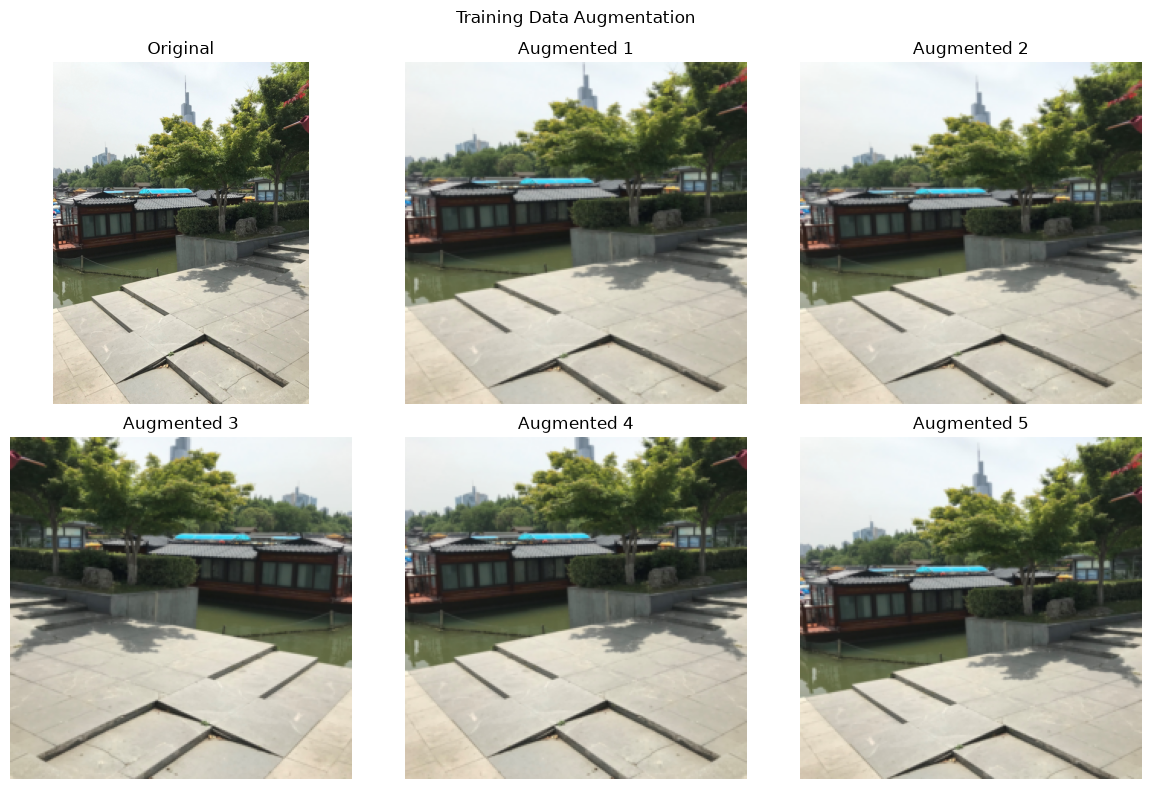

In [9]:
sample_path = next((dataset_path / "train").rglob("*.jpg"))
original = Image.open(sample_path).convert("RGB")
augmentation_only = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.75, 1.333)),
    transforms.RandomHorizontalFlip(p=0.5)
])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes[0, 0].imshow(original); axes[0, 0].set_title("Original"); axes[0, 0].axis("off")
for i in range(5):
    aug = augmentation_only(original)
    ax = axes.flat[i + 1]
    ax.imshow(aug); ax.set_title(f"Augmented {i+1}"); ax.axis("off")
plt.suptitle("Training Data Augmentation")
plt.tight_layout()
plt.show()

## 2. Exact duplicate investigation

Exact duplicates are checked using MD5 file hashes. The important case for this experiment is an identical image occurring in both training and validation. Such duplication can make validation performance less representative of performance on unseen images.

In [10]:
def md5_hash(file_path, chunk_size=1024 * 1024):
    h = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def find_cross_split_duplicates(dataset_root, split1="train", split2="val"):
    hash_to_files = defaultdict(list)
    for split in [split1, split2]:
        for file in (Path(dataset_root) / split).rglob("*"):
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:
                hash_to_files[md5_hash(file)].append((split, file))

    duplicates = defaultdict(set)
    for file_hash, files in hash_to_files.items():
        splits = {split for split, _ in files}
        if split1 in splits and split2 in splits:
            duplicates[(split1, split2)].add(file_hash)
    return duplicates

cross_split_duplicates = find_cross_split_duplicates(dataset_path)
print("Train-validation duplicate hash groups:", len(cross_split_duplicates.get(("train", "val"), set())))

Train-validation duplicate hash groups: 10


## 3. Baseline ResNet50 transfer learning

The baseline is trained on the original dataset. The ImageNet-pretrained ResNet50 backbone is frozen and only the final classification layer is trained. This is the baseline that the cleaned-data experiment must match.

In [11]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


In [21]:
def create_datasets(root):
    train_ds = datasets.ImageFolder(Path(root) / "train", transform=train_transform)
    val_ds = datasets.ImageFolder(Path(root) / "val", transform=eval_transform)
    test_ds = datasets.ImageFolder(Path(root) / "test", transform=eval_transform)
    assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx
    return train_ds, val_ds, test_ds

def create_loaders(train_ds, val_ds, test_ds):
    return (
        DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=device.type == "cuda"),
        DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=device.type == "cuda"),
        DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=device.type == "cuda")
    )

train_dataset, val_dataset, test_dataset = create_datasets(dataset_path)
train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset)
class_names = train_dataset.classes
num_classes = len(class_names)
print("Train dataset size:", len(train_dataset), "\nValidation dataset size:", len(val_dataset), "\nTest dataset size:", len(test_dataset), "\nNumber of classes:", num_classes)

Train dataset size: 3850 
Validation dataset size: 482 
Test dataset size: 472 
Number of classes: 23


In [22]:
def create_resnet50(num_classes):
    model = resnet50(weights=weights)
    for parameter in model.parameters():
        parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def create_optimizer(model):
    return torch.optim.AdamW(
        model.fc.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

model = create_resnet50(num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = create_optimizer(model)

print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Total parameters: 23555159
Trainable parameters: 47127


In [23]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.eval()
    model.fc.train()
    running_loss = correct = total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

def validate_one_epoch(model, loader, criterion):
    model.eval()
    running_loss = correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

def train_model(model, train_loader, val_loader, model_name):
    criterion = nn.CrossEntropyLoss()
    optimizer = create_optimizer(model)
    history = []
    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = -1
    best_epoch = 0
    start = time.perf_counter()

    for epoch in range(NUM_EPOCHS):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion)
        history.append({
            "epoch": epoch + 1, "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc
        })
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
        print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | Train Acc {train_acc:.4f} | Val Acc {val_acc:.4f}")

    model.load_state_dict(best_state)
    total_time = time.perf_counter() - start
    torch.save({"model_state_dict": best_state, "class_names": class_names,
                "class_to_idx": train_dataset.class_to_idx, "best_epoch": best_epoch,
                "best_val_accuracy": best_val_acc}, f"{model_name}_best.pth")
    return model, pd.DataFrame(history), best_val_acc, best_epoch, total_time

In [25]:
set_seed(42)
original_model = create_resnet50(num_classes)
original_model, original_history, original_best_val, original_best_epoch, original_time = train_model(
    original_model, train_loader, val_loader, "resnet50_original"
)
print(f"Best validation accuracy: {original_best_val:.4f} at epoch {original_best_epoch}")
print(f"Training time: {original_time/60:.2f} min")

Epoch 01/10 | Train Acc 0.3966 | Val Acc 0.5477
Epoch 02/10 | Train Acc 0.6403 | Val Acc 0.6224
Epoch 03/10 | Train Acc 0.7192 | Val Acc 0.6826
Epoch 04/10 | Train Acc 0.7621 | Val Acc 0.7075
Epoch 05/10 | Train Acc 0.7919 | Val Acc 0.7178
Epoch 06/10 | Train Acc 0.8223 | Val Acc 0.7241
Epoch 07/10 | Train Acc 0.8538 | Val Acc 0.7365
Epoch 08/10 | Train Acc 0.8610 | Val Acc 0.7573
Epoch 09/10 | Train Acc 0.8766 | Val Acc 0.7739
Epoch 10/10 | Train Acc 0.8925 | Val Acc 0.7718
Best validation accuracy: 0.7739 at epoch 9
Training time: 55.59 min


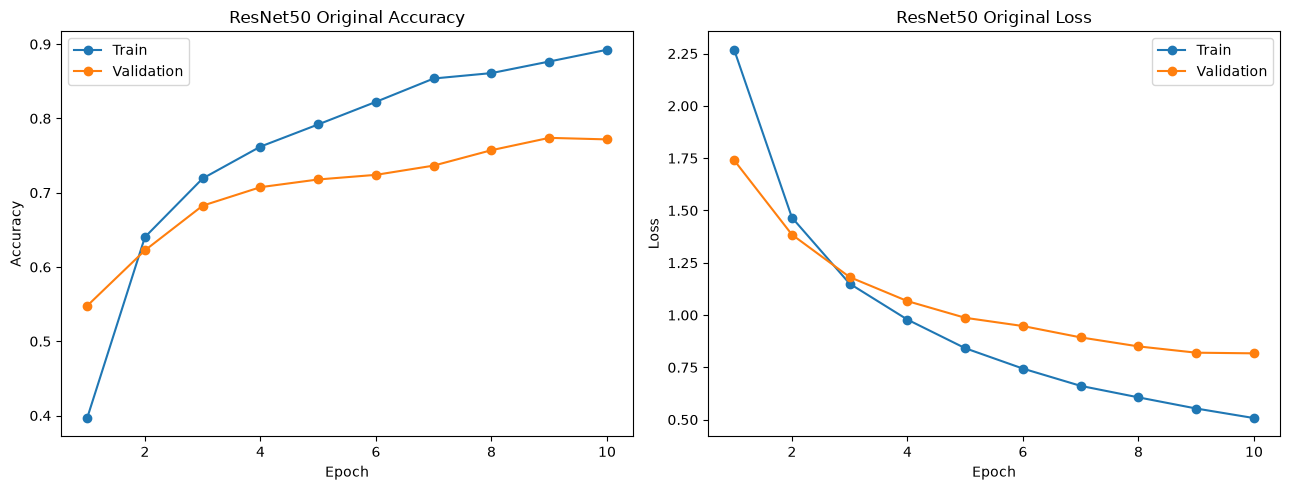

In [26]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].plot(history.epoch, history.train_accuracy, marker="o", label="Train")
    axes[0].plot(history.epoch, history.val_accuracy, marker="o", label="Validation")
    axes[0].set(title=f"{title} Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[0].legend()
    axes[1].plot(history.epoch, history.train_loss, marker="o", label="Train")
    axes[1].plot(history.epoch, history.val_loss, marker="o", label="Validation")
    axes[1].set(title=f"{title} Loss", xlabel="Epoch", ylabel="Loss")
    axes[1].legend()
    plt.tight_layout(); plt.show()

plot_history(original_history, "ResNet50 Original")

## 4. Baseline test evaluation and error analysis

The independent test set is evaluated only after model selection using validation accuracy. The test set is not used to choose hyperparameters or preprocessing.

In [27]:
def predict(model, loader):
    model.eval()
    labels, probs = [], []
    with torch.no_grad():
        for images, y in loader:
            outputs = model(images.to(device))
            labels.append(y)
            probs.append(torch.softmax(outputs, dim=1).cpu())
    return torch.cat(labels).numpy(), torch.cat(probs).numpy()

def evaluate(labels, probs, class_names):
    preds = probs.argmax(axis=1)
    metrics = {
        "Accuracy": accuracy_score(labels, preds),
        "Macro Precision": precision_score(labels, preds, average="macro", zero_division=0),
        "Macro Recall": recall_score(labels, preds, average="macro", zero_division=0),
        "Macro F1": f1_score(labels, preds, average="macro", zero_division=0)
    }
    print(pd.Series(metrics).round(4))
    print(classification_report(labels, preds, target_names=class_names, zero_division=0, digits=4))
    return metrics, preds, confusion_matrix(labels, preds, labels=range(len(class_names)))

original_labels, original_probs = predict(original_model, test_loader)
original_metrics, original_preds, original_cm = evaluate(original_labels, original_probs, class_names)
original_results = pd.DataFrame([original_metrics | {"Best Epoch": original_best_epoch, "Training Minutes": original_time/60}])
display(original_results.round(4))

Accuracy           0.7225
Macro Precision    0.7471
Macro Recall       0.7493
Macro F1           0.7425
dtype: float64
                                   precision    recall  f1-score   support

                    Acer palmatum     0.8000    0.8000    0.8000        20
                   Cedrus deodara     0.5385    0.9333    0.6829        15
                  Celtis sinensis     0.6957    0.6957    0.6957        23
 Cinnamomum camphora (Linn) Presl     0.8182    0.6207    0.7059        29
            Elaeocarpus decipiens     0.6111    0.5238    0.5641        21
                 Flowering cherry     0.7857    0.8462    0.8148        13
                    Ginkgo biloba     0.4231    0.3929    0.4074        28
          Koelreuteria paniculata     0.5862    0.6071    0.5965        28
             Lagerstroemia indica     0.8889    1.0000    0.9412         8
            Liquidambar formosana     0.6800    0.8500    0.7556        20
            Liriodendron chinense     0.5517    0.7273 

,Accuracy,Macro Precision,Macro Recall,Macro F1,Best Epoch,Training Minutes
0,0.7225,0.7471,0.7493,0.7425,9,55.5919


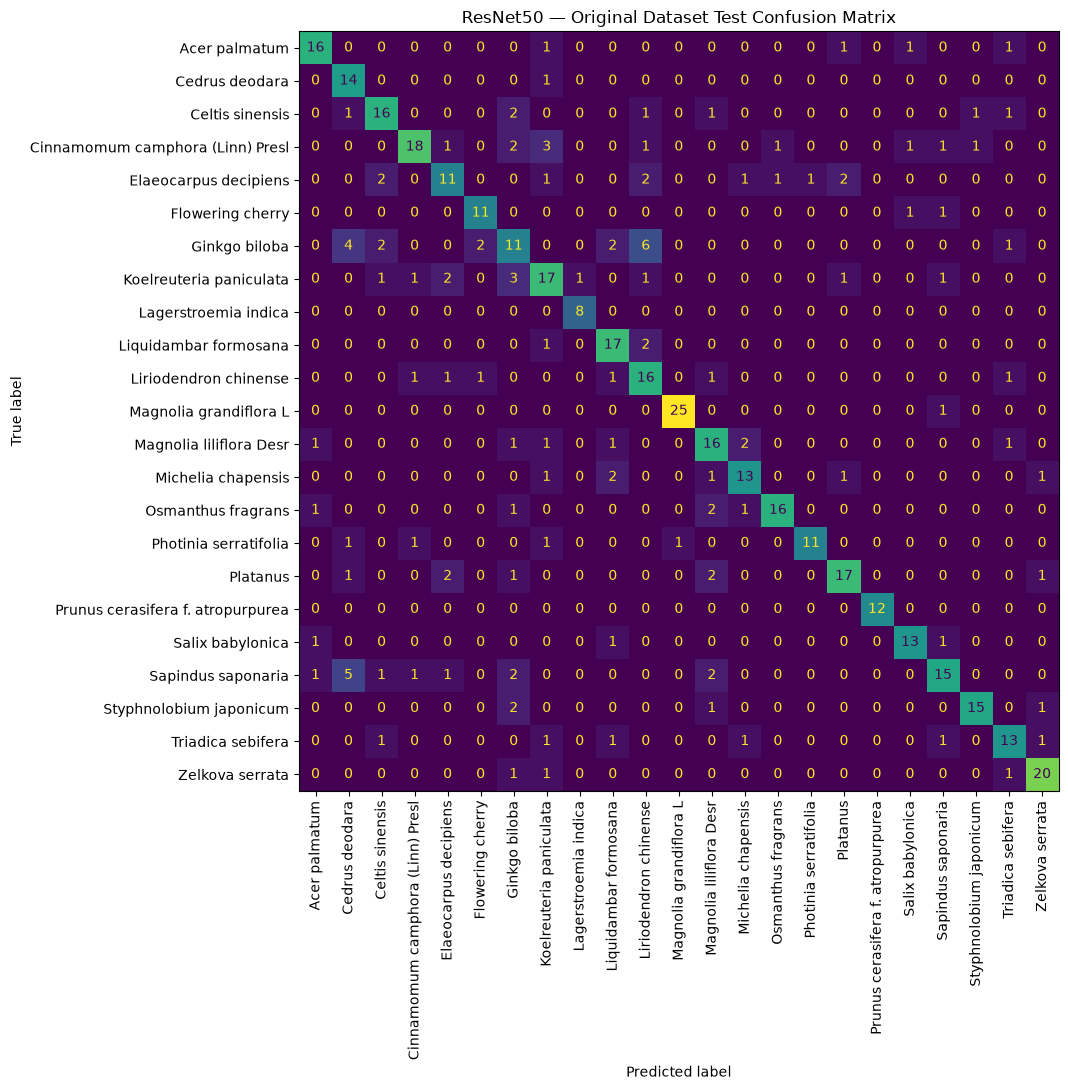

In [28]:
fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay(original_cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=90, values_format="d", colorbar=False
)
ax.set_title("ResNet50 — Original Dataset Test Confusion Matrix")
plt.tight_layout(); plt.show()

In [29]:
def top_n_accuracy(labels, probs, n):
    top_n = np.argsort(probs, axis=1)[:, -n:]
    return np.mean(np.any(top_n == labels[:, None], axis=1))

original_top_n = pd.DataFrame({
    "n": range(1, num_classes + 1),
    "accuracy": [top_n_accuracy(original_labels, original_probs, n) for n in range(1, num_classes + 1)]
})
display(original_top_n.round(4))

,n,accuracy
0,1,0.7225
1,2,0.8347
2,3,0.8941
3,4,0.9131
4,5,0.9280
5,6,0.9513
6,7,0.9534
7,8,0.9597
8,9,0.9767
9,10,0.9873


In [30]:
incorrect = np.where(original_preds != original_labels)[0]
error_analysis_df = pd.DataFrame({
    "index": incorrect,
    "true_label": [class_names[i] for i in original_labels[incorrect]],
    "predicted_label": [class_names[i] for i in original_preds[incorrect]],
    "confidence": [original_probs[i, original_preds[i]] for i in incorrect],
    "true_class_probability": [original_probs[i, original_labels[i]] for i in incorrect]
}).sort_values("confidence", ascending=False).reset_index(drop=True)

print("Incorrect predictions:", len(error_analysis_df))
display(error_analysis_df.head(20))

Incorrect predictions: 131


,index,true_label,predicted_label,confidence,true_class_probability
0,156,Koelreuteria paniculata,Liriodendron chinense,0.929273,0.028756
1,162,Koelreuteria paniculata,Ginkgo biloba,0.884413,0.032644
2,127,Ginkgo biloba,Liriodendron chinense,0.801058,0.115704
3,215,Liriodendron chinense,Triadica sebifera,0.798845,0.144402
4,346,Platanus,Magnolia liliflora Desr,0.764821,0.213375
5,378,Salix babylonica,Acer palmatum,0.759700,0.060275
6,136,Ginkgo biloba,Liquidambar formosana,0.752579,0.083839
7,198,Liquidambar formosana,Liriodendron chinense,0.751231,0.102261
8,466,Zelkova serrata,Triadica sebifera,0.728415,0.094363
9,31,Cedrus deodara,Koelreuteria paniculata,0.700436,0.080542


In [31]:
high_confidence_errors = error_analysis_df[error_analysis_df["confidence"] > 0.80].copy()
print("High-confidence errors (>80%):", len(high_confidence_errors))
display(high_confidence_errors)

High-confidence errors (>80%): 3


,index,true_label,predicted_label,confidence,true_class_probability
0,156,Koelreuteria paniculata,Liriodendron chinense,0.929273,0.028756
1,162,Koelreuteria paniculata,Ginkgo biloba,0.884413,0.032644
2,127,Ginkgo biloba,Liriodendron chinense,0.801058,0.115704


### Interpretation of the baseline errors

High-confidence errors are inspected as individual cases rather than treated as proof of a specific data problem. A wrong prediction with high confidence may reflect visually similar species, viewpoint, lighting, background, or other image-specific characteristics. The error analysis therefore guides further investigation but does not by itself justify changing the preprocessing pipeline.

## 5. Controlled cleaned-data experiment

The duplicate analysis found exact train/validation duplicate hash groups. For the second experiment, only the **training copies** of those exact duplicates are removed. Validation and test images remain unchanged.

**Important experimental decision:** the cleaned experiment is another transfer-learning run with the same frozen ResNet50 setup. It should **not** be changed to fine-tuning. Fine-tuning would introduce a second independent variable, so any performance difference could no longer be attributed to duplicate removal.

In [32]:
def duplicate_train_files(dataset_root, duplicate_hashes):
    matches = []
    for file in (Path(dataset_root) / "train").rglob("*"):
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:
            if md5_hash(file) in duplicate_hashes:
                matches.append(file)
    return matches

duplicate_hashes = cross_split_duplicates.get(("train", "val"), set())
train_duplicate_files = duplicate_train_files(dataset_path, duplicate_hashes)
print("Duplicate hash groups:", len(duplicate_hashes))
print("Training files to remove:", len(train_duplicate_files))

Duplicate hash groups: 10
Training files to remove: 13


In [33]:
# Rebuild the separate cleaned copy only when it does not already exist.
# The original dataset is never modified.
if not cleaned_dataset_path.exists():
    shutil.copytree(dataset_path, cleaned_dataset_path)
    print("Created:", cleaned_dataset_path)
else:
    print("Using existing cleaned copy:", cleaned_dataset_path)

removed = []
for original_file in train_duplicate_files:
    relative = original_file.relative_to(dataset_path)
    cleaned_file = cleaned_dataset_path / relative
    if cleaned_file.exists():
        cleaned_file.unlink()
        removed.append(cleaned_file)

print("Files removed from cleaned train split:", len(removed))

Using existing cleaned copy: D:\NEUTRAL_TOMMI\GROUPPROJECT\cleaned_dataset
Files removed from cleaned train split: 0


In [34]:
cleaned_counts = {split: count_images(cleaned_dataset_path / split) for split in ["train", "val", "test"]}
print("Original counts:", counts)
print("Cleaned counts:", cleaned_counts)
assert cleaned_counts["val"] == counts["val"]
assert cleaned_counts["test"] == counts["test"]

remaining = find_cross_split_duplicates(cleaned_dataset_path)
print("Remaining train-validation duplicate groups:", len(remaining.get(("train", "val"), set())))

Original counts: {'train': 3850, 'val': 482, 'test': 472}
Cleaned counts: {'train': 3837, 'val': 482, 'test': 472}
Remaining train-validation duplicate groups: 0


### Train the cleaned model

The cleaned model is trained with exactly the same experimental settings as the baseline. The random seed is reset before training to make the comparison more reproducible. The test set is still untouched.

In [35]:
cleaned_train_dataset, cleaned_val_dataset, cleaned_test_dataset = create_datasets(cleaned_dataset_path)
cleaned_train_loader, cleaned_val_loader, cleaned_test_loader = create_loaders(
    cleaned_train_dataset, cleaned_val_dataset, cleaned_test_dataset
)
assert cleaned_train_dataset.class_to_idx == train_dataset.class_to_idx

set_seed(42)
cleaned_model = create_resnet50(num_classes)
cleaned_model, cleaned_history, cleaned_best_val, cleaned_best_epoch, cleaned_time = train_model(
    cleaned_model, cleaned_train_loader, cleaned_val_loader, "resnet50_cleaned"
)
print(f"Best validation accuracy: {cleaned_best_val:.4f} at epoch {cleaned_best_epoch}")
print(f"Training time: {cleaned_time/60:.2f} min")

Epoch 01/10 | Train Acc 0.4058 | Val Acc 0.5394
Epoch 02/10 | Train Acc 0.6330 | Val Acc 0.6058
Epoch 03/10 | Train Acc 0.7183 | Val Acc 0.6680
Epoch 04/10 | Train Acc 0.7550 | Val Acc 0.6826
Epoch 05/10 | Train Acc 0.7954 | Val Acc 0.7095
Epoch 06/10 | Train Acc 0.8256 | Val Acc 0.7199
Epoch 07/10 | Train Acc 0.8449 | Val Acc 0.7344
Epoch 08/10 | Train Acc 0.8645 | Val Acc 0.7573
Epoch 09/10 | Train Acc 0.8770 | Val Acc 0.7801
Epoch 10/10 | Train Acc 0.8877 | Val Acc 0.7759
Best validation accuracy: 0.7801 at epoch 9
Training time: 74.69 min


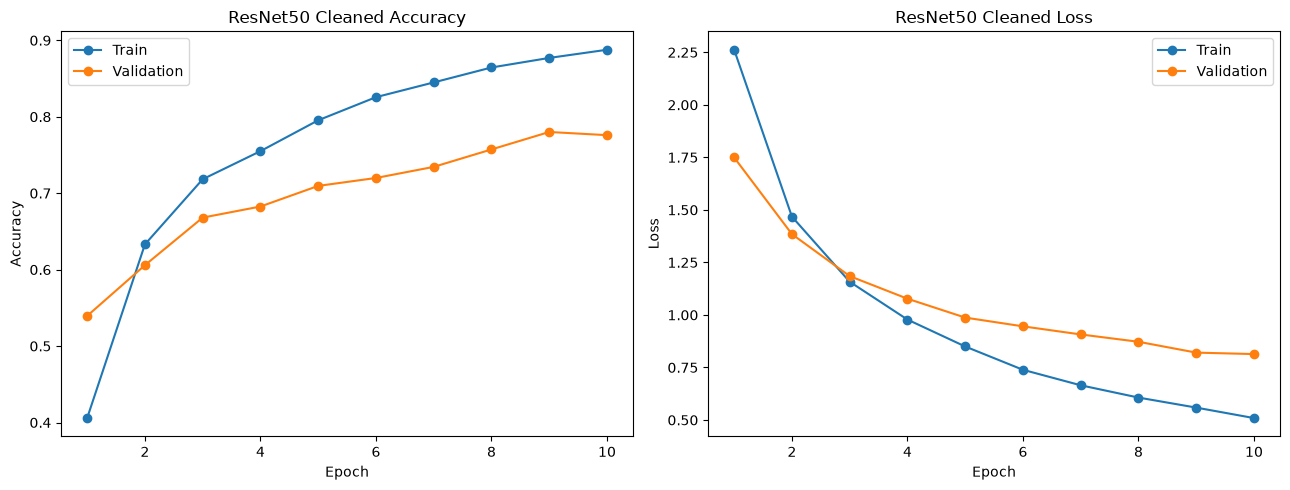

In [36]:
plot_history(cleaned_history, "ResNet50 Cleaned")

In [37]:
cleaned_labels, cleaned_probs = predict(cleaned_model, cleaned_test_loader)
cleaned_metrics, cleaned_preds, cleaned_cm = evaluate(cleaned_labels, cleaned_probs, class_names)
cleaned_results = pd.DataFrame([cleaned_metrics | {"Best Epoch": cleaned_best_epoch, "Training Minutes": cleaned_time/60}])
display(cleaned_results.round(4))

Accuracy           0.7182
Macro Precision    0.7399
Macro Recall       0.7458
Macro F1           0.7367
dtype: float64
                                   precision    recall  f1-score   support

                    Acer palmatum     0.7619    0.8000    0.7805        20
                   Cedrus deodara     0.7000    0.9333    0.8000        15
                  Celtis sinensis     0.6207    0.7826    0.6923        23
 Cinnamomum camphora (Linn) Presl     0.8182    0.6207    0.7059        29
            Elaeocarpus decipiens     0.6471    0.5238    0.5789        21
                 Flowering cherry     0.5789    0.8462    0.6875        13
                    Ginkgo biloba     0.6000    0.4286    0.5000        28
          Koelreuteria paniculata     0.5769    0.5357    0.5556        28
             Lagerstroemia indica     0.8889    1.0000    0.9412         8
            Liquidambar formosana     0.5862    0.8500    0.6939        20
            Liriodendron chinense     0.5769    0.6818 

,Accuracy,Macro Precision,Macro Recall,Macro F1,Best Epoch,Training Minutes
0,0.7182,0.7399,0.7458,0.7367,9,74.6896


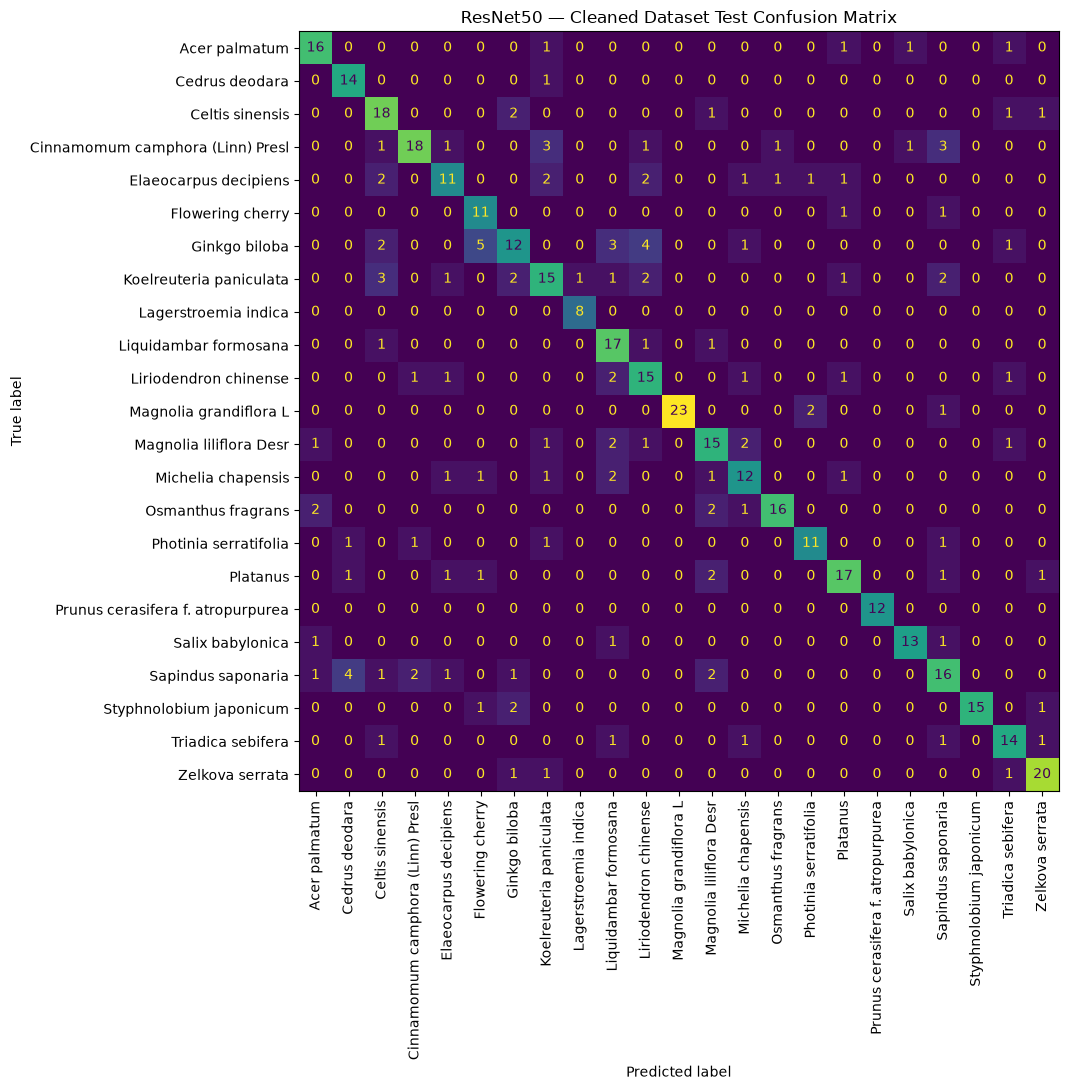

In [38]:
fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay(cleaned_cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=90, values_format="d", colorbar=False
)
ax.set_title("ResNet50 — Cleaned Dataset Test Confusion Matrix")
plt.tight_layout(); plt.show()

In [39]:
cleaned_top_n = pd.DataFrame({
    "n": range(1, num_classes + 1),
    "accuracy": [top_n_accuracy(cleaned_labels, cleaned_probs, n) for n in range(1, num_classes + 1)]
})

top_n_comparison = original_top_n.rename(columns={"accuracy": "Original"}).merge(
    cleaned_top_n.rename(columns={"accuracy": "Cleaned"}), on="n"
)
top_n_comparison["Difference"] = top_n_comparison["Cleaned"] - top_n_comparison["Original"]
display(top_n_comparison.round(4))

,n,Original,Cleaned,Difference
0,1,0.7225,0.7182,-0.0042
1,2,0.8347,0.8220,-0.0127
2,3,0.8941,0.8877,-0.0064
3,4,0.9131,0.9174,0.0042
4,5,0.9280,0.9407,0.0127
5,6,0.9513,0.9576,0.0064
6,7,0.9534,0.9597,0.0064
7,8,0.9597,0.9619,0.0021
8,9,0.9767,0.9682,-0.0085
9,10,0.9873,0.9809,-0.0064


## 6. Final comparison

This table isolates the effect of removing exact train/validation duplicates. Because the validation and test sets are unchanged and the model/training settings are kept constant, differences can be interpreted as evidence about the impact of duplicate removal rather than a change from transfer learning to fine-tuning.

In [40]:
comparison = pd.DataFrame({
    "Original": [
        len(train_dataset), original_best_val, original_metrics["Accuracy"],
        original_metrics["Macro Precision"], original_metrics["Macro Recall"], original_metrics["Macro F1"]
    ],
    "Cleaned": [
        len(cleaned_train_dataset), cleaned_best_val, cleaned_metrics["Accuracy"],
        cleaned_metrics["Macro Precision"], cleaned_metrics["Macro Recall"], cleaned_metrics["Macro F1"]
    ]
}, index=[
    "Training images", "Best validation accuracy", "Test accuracy",
    "Macro precision", "Macro recall", "Macro F1"
])

comparison["Difference (Cleaned - Original)"] = comparison["Cleaned"] - comparison["Original"]
display(comparison.round(4))

,Original,Cleaned,Difference (Cleaned - Original)
Training images,3850.0000,3837.0000,-13.0000
Best validation accuracy,0.7739,0.7801,0.0062
Test accuracy,0.7225,0.7182,-0.0042
Macro precision,0.7471,0.7399,-0.0072
Macro recall,0.7493,0.7458,-0.0034
Macro F1,0.7425,0.7367,-0.0058


In [41]:
original_errors = np.sum(original_preds != original_labels)
cleaned_errors = np.sum(cleaned_preds != cleaned_labels)
original_high_conf = np.sum(original_probs[np.arange(len(original_labels)), original_preds] > 0.80) - np.sum((original_preds == original_labels) & (original_probs[np.arange(len(original_labels)), original_preds] > 0.80))
cleaned_high_conf = np.sum(cleaned_probs[np.arange(len(cleaned_labels)), cleaned_preds] > 0.80) - np.sum((cleaned_preds == cleaned_labels) & (cleaned_probs[np.arange(len(cleaned_labels)), cleaned_preds] > 0.80))

print(f"Original incorrect predictions: {original_errors}")
print(f"Cleaned incorrect predictions: {cleaned_errors}")
print(f"Original high-confidence errors: {original_high_conf}")
print(f"Cleaned high-confidence errors: {cleaned_high_conf}")

Original incorrect predictions: 131
Cleaned incorrect predictions: 133
Original high-confidence errors: 3
Cleaned high-confidence errors: 3


## 7. Conclusions

The final conclusion should be based on the measured results above. The cleaned-data experiment should be described as a **controlled duplicate-removal experiment**, not as a fine-tuning experiment.

If performance is similar, the appropriate conclusion is that removing the exact train/validation duplicates did not materially change ResNet50 performance under this setup. If performance changes, report the direction and size of the change without claiming that duplicate removal is universally beneficial.

The ResNet50 results can then be compared with the team's ResNet18 and ResNet34 results in the final project report. The full n-best table is provided so the team can identify where the models begin to separate in top-n accuracy.